In [4]:
import pandas as pd
nist_spectra_df = pd.read_pickle('../../data/proc/nist20mona23v3/spec_df.pkl')
nist_spectra_df

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,res,ace,nce,prec_mz,peaks,ri,group_id
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,2,8.0,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,2,10.0,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,2,14.0,NaN,1467.0061,"[(537.39, 55.94), (599.5, 999.0), (600.51, 42....",NaN,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,2,16.0,NaN,1467.0061,"[(597.46, 41.86), (598.5, 45.15), (599.51, 999...",NaN,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,2,20.0,NaN,1467.0061,"[(598.49, 47.85), (599.5, 999.0), (600.5, 85.5...",NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1148067,1155605,8926,[M+H]+,FT,HCD,MS2,P,mona23,AC000010,NaN,4,NaN,50.0,506.3318,"[(56.0502, 37.264882), (57.0706, 38.137391), (...",NaN,214092
1148068,1155606,8926,[M+H]+,FT,HCD,MS2,P,mona23,AC000009,NaN,4,NaN,35.0,506.3318,"[(56.0502, 8.156297), (57.0706, 10.644887), (6...",NaN,214092
1148069,1155607,8926,[M+H]+,FT,HCD,MS2,P,mona23,AC000008,NaN,4,NaN,30.0,506.3318,"[(56.0502, 4.315988), (57.0706, 5.02635), (60....",NaN,214092
1148070,1155608,8926,[M+H]+,FT,HCD,MS2,P,mona23,AC000007,NaN,4,NaN,20.0,506.3318,"[(276.2686, 3.505299), (294.2792, 24.68621), (...",NaN,214092


In [5]:
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'].isin(['nist20_hr'])]
nist_spectra_df.shape

(1005897, 17)

In [6]:
nist_spectra_df['ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)

/tmp/ipykernel_31164/1389500530.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nist_spectra_df['ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)


In [7]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = nist_spectra_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 6091

Top adduct types:

prec_type
[M+H]+                       311072
[M-H]-                       123854
[M+H-H2O]+                    84118
[M+Na]+                       38337
[2M+H]+                       28761
                              ...  
[M+H-CH6O2-C2H6O3-CO]+            1
[M+H-CH6O2-CH4O2-C4H4O2]+         1
[M+H-CH6O2-H2O]+                  1
[M-H-C4H8O4-CH4O]-                1
[M+H-C5H8O2-C5H10O2]+             1
Name: count, Length: 6091, dtype: int64


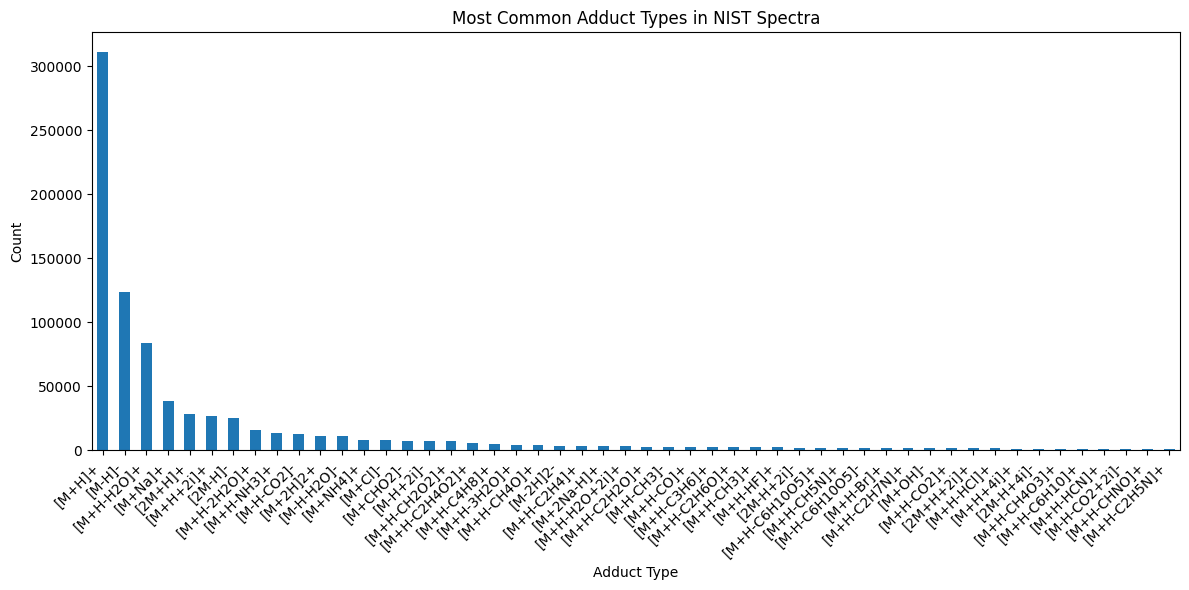

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
adduct_counts.head(50).plot(kind='bar')
plt.title('Most Common Adduct Types in NIST Spectra')
plt.ylabel('Count')
plt.xlabel('Adduct Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

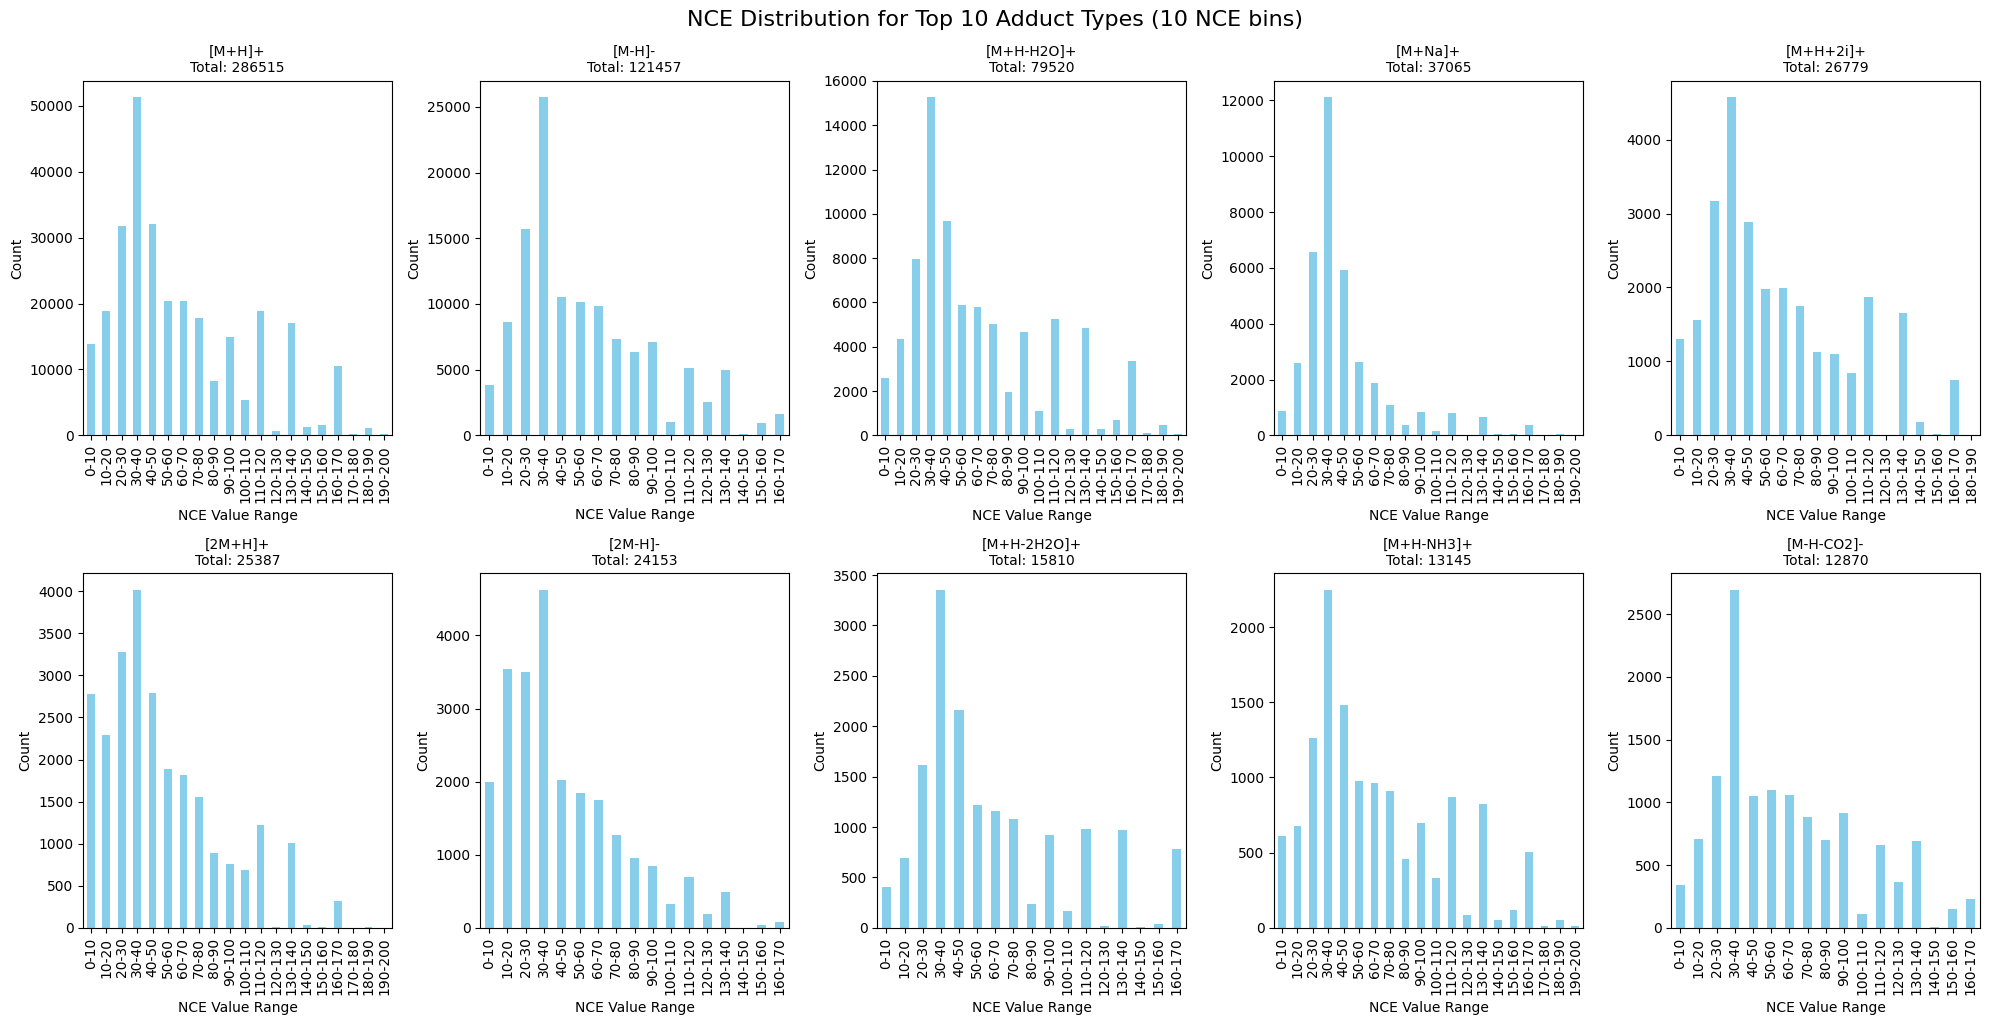

In [9]:
import numpy as np

prec_type_nce_counts = nist_spectra_df.groupby(['prec_type', 'nce']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_nce_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define NCE bins
nce_bin_size = 10
bins = np.arange(0, 325, nce_bin_size)
bin_labels = [f"{b}-{b+nce_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_nce_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('NCE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'NCE Distribution for Top 10 Adduct Types ({nce_bin_size} NCE bins)', fontsize=16, y=1.02)
plt.show()

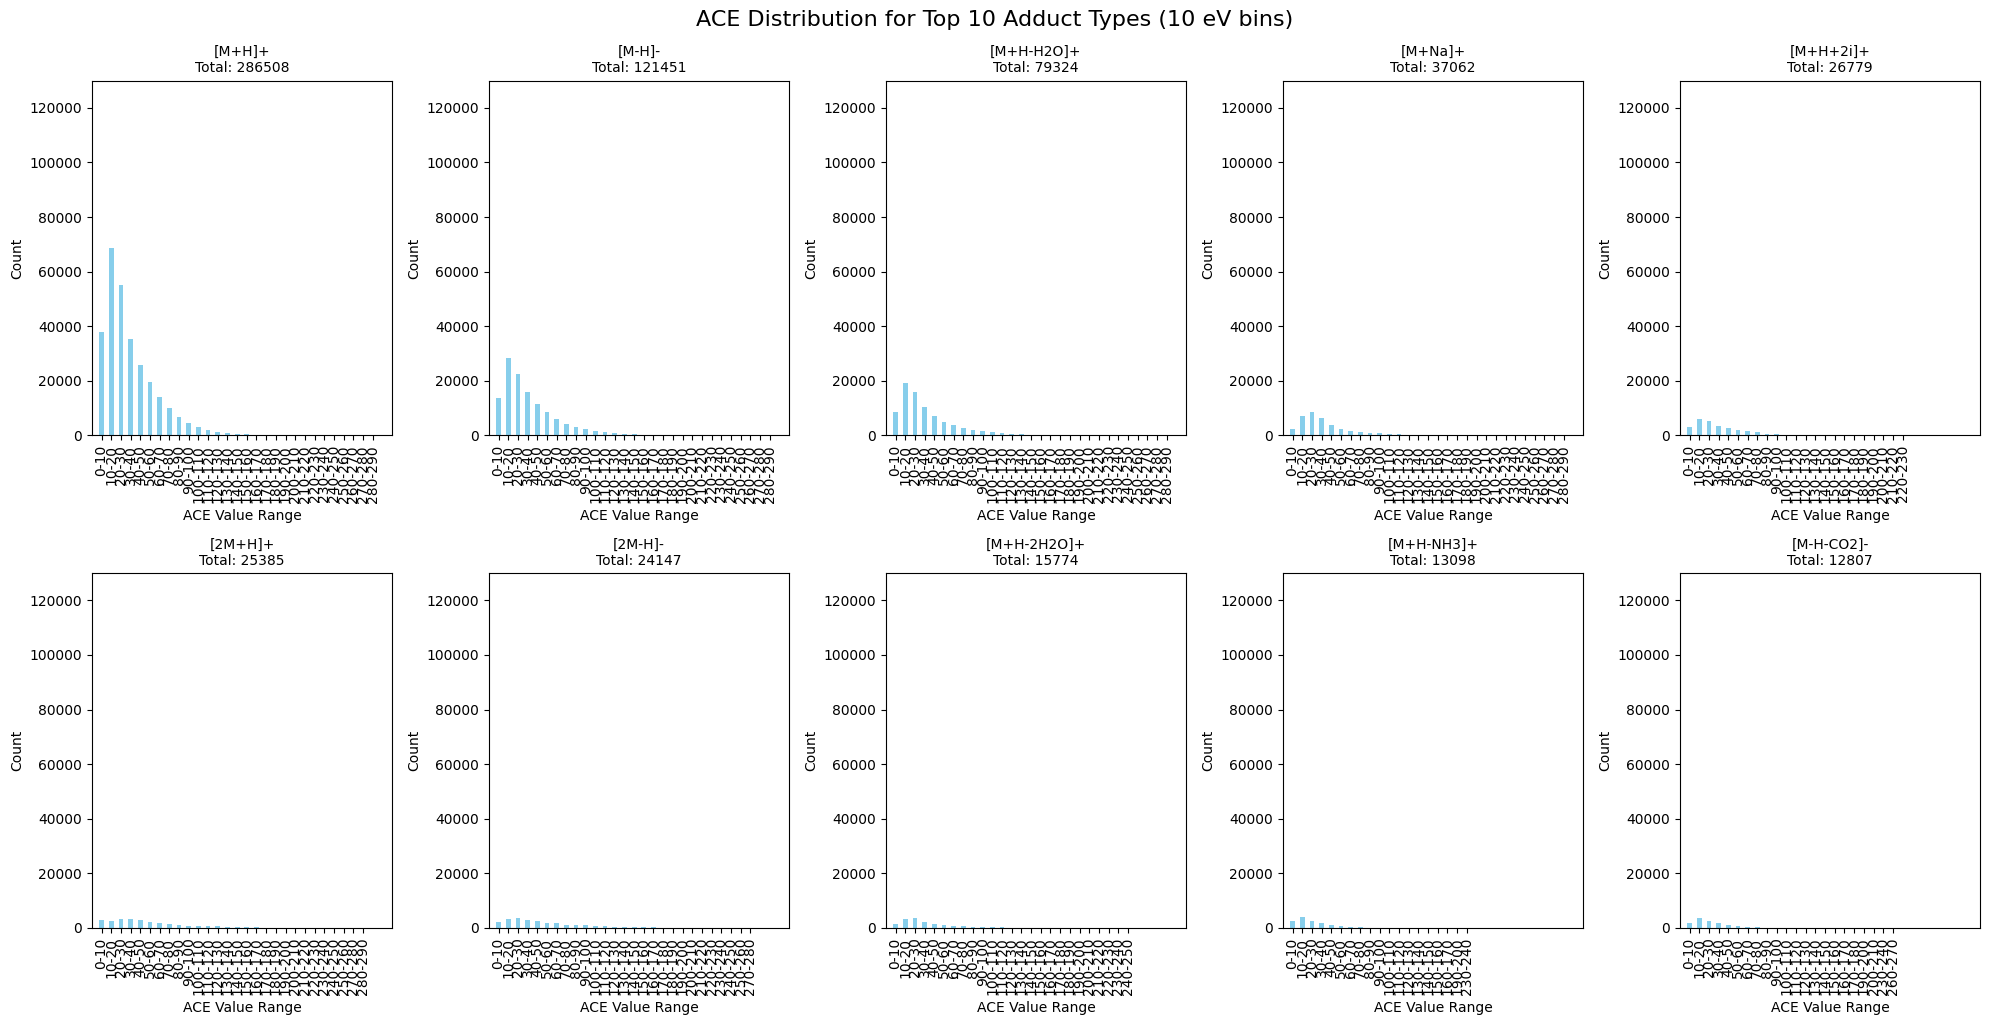

In [10]:
import numpy as np

prec_type_ace_counts = nist_spectra_df.groupby(['prec_type', 'ace']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_ace_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define ACE bins
ace_bin_size = 10
bins = np.arange(0, 300, ace_bin_size)
bin_labels = [f"{b}-{b+ace_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_ace_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('ACE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 130_000)
    
    ax.set_xlim(-1, 30)
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'ACE Distribution for Top 10 Adduct Types ({ace_bin_size} eV bins)', fontsize=16, y=1.02)
plt.show()

In [11]:
nist_mol_df = pd.read_pickle('../../data/proc/nist20mona23v3/mol_df.pkl')
nist_mol_df.head()

,smiles,mol_id,mol,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,<rdkit.Chem.rdchem.Mol object at 0x7f16bc20ad90>,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC1=CCN(Cc2ccccc2)CC1,1,<rdkit.Chem.rdchem.Mol object at 0x7f16bc20ae30>,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
2,BrC1CCCCCC(Br)C12OCCO2,2,<rdkit.Chem.rdchem.Mol object at 0x7f16bc20aed0>,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0
3,BrC1CCN(Cc2ccccc2)C1,3,<rdkit.Chem.rdchem.Mol object at 0x7f175a09f1a0>,VOXJTPBOJBQGSL,c1ccc(CN2CCCC2)cc1,C11H14BrN,InChI=1S/C11H14BrN/c12-11-6-7-13(9-11)8-10-4-2...,240.144,239.030962,13,14,0,True,0
4,BrC=C(c1ccccc1)c1ccccc1,4,<rdkit.Chem.rdchem.Mol object at 0x7f16bd30c3b0>,QRDVTIMUEDYLOC,C=C(c1ccccc1)c1ccccc1,C14H11Br,InChI=1S/C14H11Br/c15-11-14(12-7-3-1-4-8-12)13...,259.146,258.004412,15,16,0,True,0


In [12]:
nist_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')
nist_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0


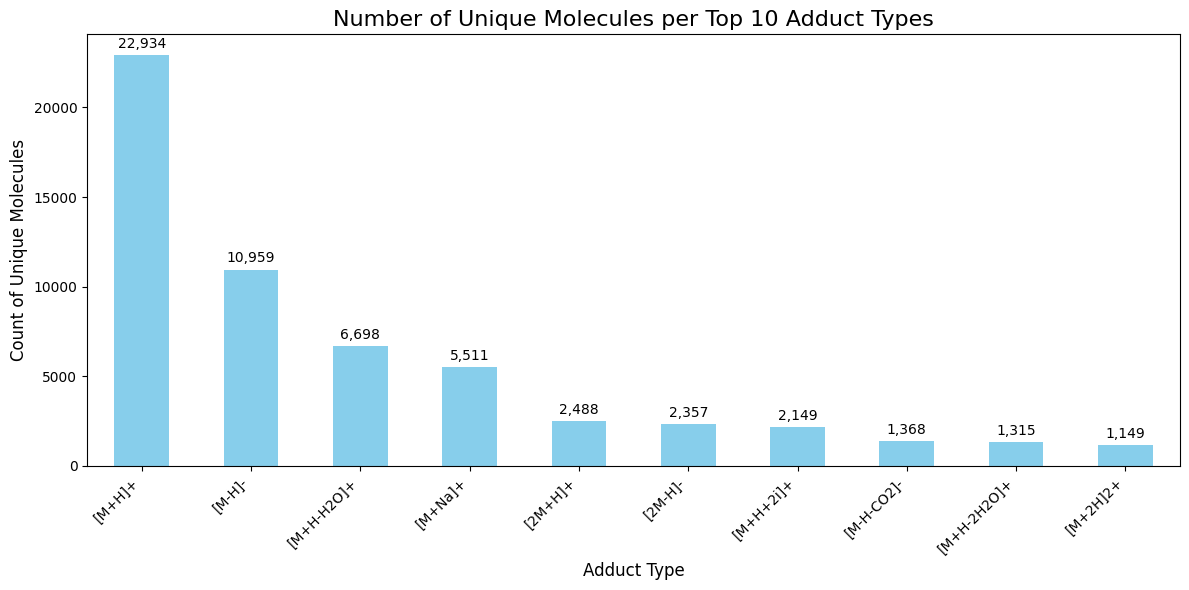

Number of unique molecules per adduct type:
prec_type
[M+H]+         22934
[M-H]-         10959
[M+H-H2O]+      6698
[M+Na]+         5511
[2M+H]+         2488
[2M-H]-         2357
[M+H+2i]+       2149
[M-H-CO2]-      1368
[M+H-2H2O]+     1315
[M+2H]2+        1149
Name: mol_id, dtype: int64


In [13]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = nist_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(10)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 10 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)